# FairFare India v2: fare fairness from 7 years of listings

Given a flight's stops and date, estimate the **expected fare** and a **fair-price band**, then label a quoted price as *underpriced*, *fair* or *overpriced*.

**Data:** `flights.csv`, 15,000 domestic fare listings, 20 cities, 2019-01-01 to 2025-12-28.

**Approach:** (1) a baseline fare per stop count, (2) a weekly **fare index** (what is left after removing the stops effect), forecast with time-series models, (3) a band from out-of-sample errors.

## 1. Load and audit

In [1]:
import warnings
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import HistGradientBoostingRegressor
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox

DATA, OUT = Path("../data/flights.csv"), Path("../artifacts")
OUT.mkdir(exist_ok=True)
H = 13                                  # forecast horizon (weeks)
BLUE, ORANGE, INK, GREY = "#2a78d6", "#eb6834", "#0e1726", "#8a93a3"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e3e7ee", "grid.linewidth": 0.8, "axes.edgecolor": "#b9bfcc", "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 10,
})

In [2]:
raw = pd.read_csv(DATA, parse_dates=["date_of_journey"])
df = raw.drop(columns="index").rename(columns={
    "date_of_journey": "date", "Source": "origin", "destination": "dest", "Total_stops": "stops",
    "Price": "price", "Duration": "duration", "Additional_info": "info"})
df["dep_hr"] = df.dep_time.str[:2].astype(int)
df["dur_min"] = df.duration.str.extract(r"(\d+)h")[0].astype(float) * 60 + df.duration.str.extract(r"(\d+)min")[0].astype(float)
df["n_stops"] = df.stops.map({"non-stop": 0, "1 stop": 1, "2 stops": 2, "3 stops": 3})

def mins(t): h, m = t.split(":"); return int(h) * 60 + int(m)
calc = (df.Arrival_time.map(mins) - df.dep_time.map(mins)) % 1440

audit = pd.Series({
    "rows": len(df), "columns": raw.shape[1], "date range": f"{df.date.min():%Y-%m-%d} to {df.date.max():%Y-%m-%d}",
    "missing values": int(df.isna().sum().sum()), "exact duplicates": int(df.drop(columns=[]).duplicated().sum()),
    "origin == destination": int((df.origin == df.dest).sum()),
    "duration matches dep/arrival times": f"{(calc == df.dur_min).mean():.1%}",
    "non-stop flights longer than 6 h": f"{((df.n_stops == 0) & (df.dur_min > 360)).mean() / (df.n_stops == 0).mean():.0%}",
    "route hops consistent with stops": f"{(df.route.str.count('-') == df.n_stops + 1).mean():.0%}",
}, name="value")
audit.to_frame()

,value
rows,15000
columns,12
date range,2019-01-01 to 2025-12-28
missing values,0
exact duplicates,0
origin == destination,0
duration matches dep/arrival times,0.1%
non-stop flights longer than 6 h,65%
route hops consistent with stops,100%


Duration does not agree with departure and arrival times, so duration and arrival time are **not reliable inputs**. The checks below show whether they matter anyway.

## 2. What drives price?

In [3]:
df["wk"] = (df.date - df.date.min().to_period("W").start_time).dt.days // 7
START_W = df.date.min().to_period("W").start_time
N_WEEKS = int(df.wk.max()) + 1
stop_mean = df.groupby("stops").price.mean()
df["resid"] = df.price - df.stops.map(stop_mean)
df["pair"] = df.origin + " > " + df.dest
df["month"], df["year"], df["dow"] = df.date.dt.month, df.date.dt.year, df.date.dt.dayofweek

def anova(col, target):
    return stats.f_oneway(*[g[target].values for _, g in df.groupby(col)]).pvalue

rows = [("Number of stops", "ANOVA on price", anova("stops", "price"))]
for label, col in [("Airline", "airline"), ("Origin city", "origin"), ("Destination city", "dest"), ("Route", "pair"),
                   ("Departure hour", "dep_hr"), ("Extra info", "info"), ("Month", "month"), ("Year", "year"), ("Day of week", "dow")]:
    rows.append((label, "ANOVA after removing stops", anova(col, "resid")))
rows.append(("Duration", "correlation after removing stops", stats.pearsonr(df.dur_min, df.resid)[1]))
drivers = pd.DataFrame(rows, columns=["factor", "test", "p_value"])
drivers["effect"] = np.where(drivers.p_value < 0.01, "Moves price", "No effect")
drivers.assign(p_value=drivers.p_value.map("{:.3f}".format)).set_index("factor")

,test,p_value,effect
factor,,,
Number of stops,ANOVA on price,0.000,Moves price
Airline,ANOVA after removing stops,0.068,No effect
Origin city,ANOVA after removing stops,0.998,No effect
Destination city,ANOVA after removing stops,0.729,No effect
Route,ANOVA after removing stops,0.402,No effect
Departure hour,ANOVA after removing stops,0.639,No effect
Extra info,ANOVA after removing stops,0.689,No effect
Month,ANOVA after removing stops,0.159,No effect
Year,ANOVA after removing stops,0.873,No effect


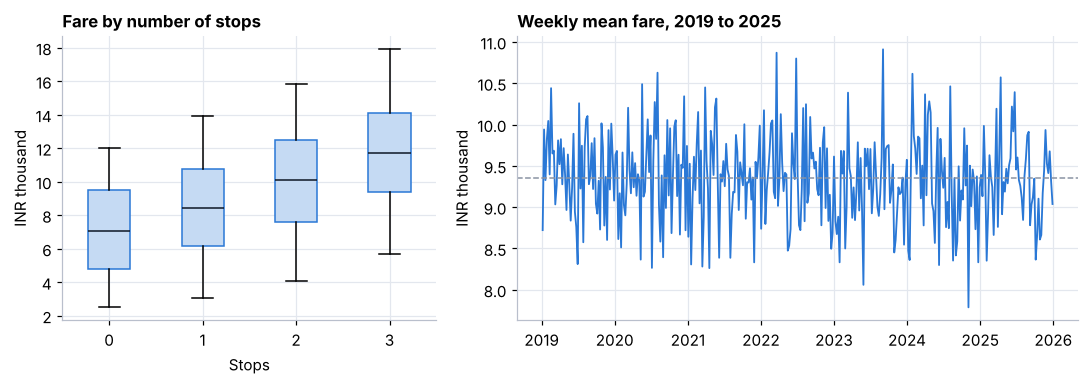

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [1, 1.5]})
order = ["non-stop", "1 stop", "2 stops", "3 stops"]
axes[0].boxplot([df[df.stops == s].price / 1000 for s in order], showfliers=False,
                patch_artist=True, boxprops=dict(facecolor="#c5daf3", color=BLUE), medianprops=dict(color=INK))
axes[0].set_xticks([1, 2, 3, 4]); axes[0].set_xticklabels(["0", "1", "2", "3"])
axes[0].set_title("Fare by number of stops"); axes[0].set_xlabel("Stops"); axes[0].set_ylabel("INR thousand")
weekly = df.set_index("date").price.resample("W").mean() / 1000
axes[1].plot(weekly.index, weekly.values, color=BLUE, lw=1.2)
axes[1].axhline(df.price.mean() / 1000, color=GREY, ls="--", lw=1)
axes[1].set_title("Weekly mean fare, 2019 to 2025"); axes[1].set_ylabel("INR thousand")
plt.tight_layout(); plt.show()

Only the **number of stops** moves the fare. Airline, origin, destination, route, departure time, duration and calendar effects are all indistinguishable from zero, and weekly fares fluctuate around one level with no trend.

## 3. Fare index and time-series diagnostics

The **fare index** is the weekly mean of price minus the stops baseline. It is the time series we analyse and forecast.

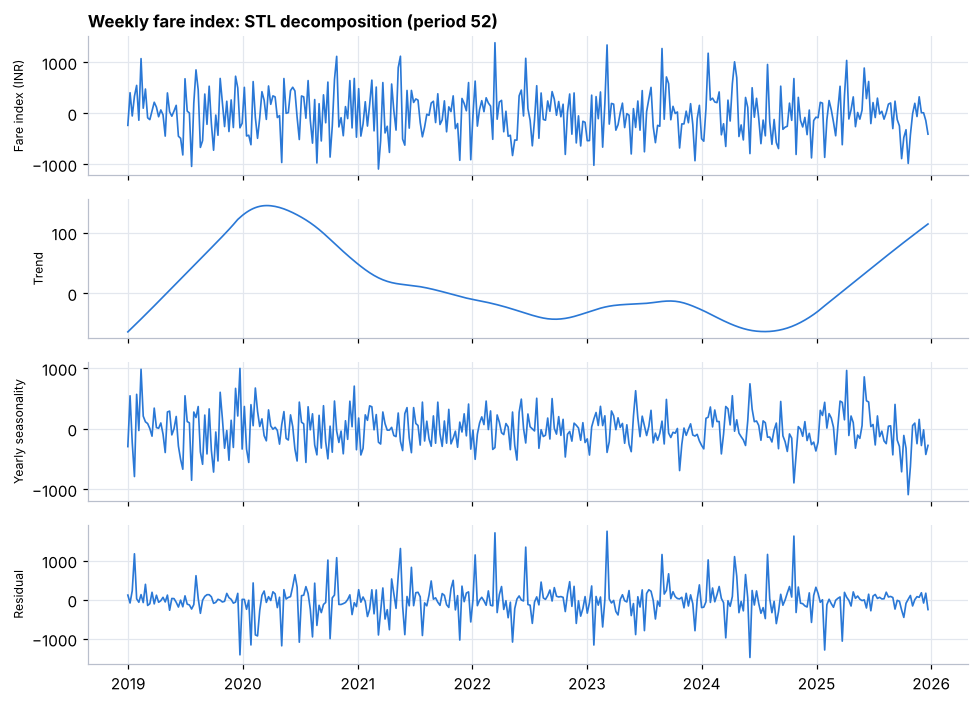

In [5]:
def weekly_index(d, base):
    s = (d.price - d.stops.map(base)).groupby(d.wk).mean()
    return s.reindex(range(int(d.wk.min()), int(d.wk.max()) + 1)).interpolate()

idx = weekly_index(df, stop_mean)
idx.index = START_W + pd.to_timedelta(idx.index * 7, unit="D")
stl = STL(idx, period=52, robust=True).fit()

fig, axes = plt.subplots(4, 1, figsize=(9, 6.5), sharex=True)
for ax, (name, s) in zip(axes, [("Fare index (INR)", idx), ("Trend", stl.trend), ("Yearly seasonality", stl.seasonal), ("Residual", stl.resid)]):
    ax.plot(s.index, s.values, color=BLUE, lw=1.1); ax.set_ylabel(name, fontsize=8)
axes[0].set_title("Weekly fare index: STL decomposition (period 52)")
plt.tight_layout(); plt.show()

In [6]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    diag = {
        "ADF p (stationary if small)": adfuller(idx)[1],
        "KPSS p (stationary if large)": kpss(idx, regression="c")[1],
        "Ljung-Box p, 26 lags (white noise if large)": acorr_ljungbox(idx, lags=[26]).lb_pvalue.iloc[0],
        "Index std (INR)": idx.std(),
        "Expected std from sampling noise alone (INR)": df.resid.std() / np.sqrt(len(df) / N_WEEKS),
        "STL trend strength": max(0, 1 - stl.resid.var() / (stl.resid + stl.trend).var()),
        "STL seasonal strength": max(0, 1 - stl.resid.var() / (stl.resid + stl.seasonal).var()),
    }
pd.Series(diag, name="value").round(3).to_frame()

,value
ADF p (stationary if small),0.000
KPSS p (stationary if large),0.100
"Ljung-Box p, 26 lags (white noise if large)",0.909
Index std (INR),449.755
Expected std from sampling noise alone (INR),437.603
STL trend strength,0.000
STL seasonal strength,0.153


The index is stationary, has no autocorrelation, and its spread equals what sampling noise alone would produce. There is **no trend, no meaningful yearly seasonality (strength about 0.15) and no autocorrelation to exploit**. Time-series models can at best match a constant level, and the backtest below checks exactly that.

## 4. Stage 1: baseline fare model

In [7]:
train, test = df[df.year < 2025], df[df.year == 2025]
rmse = lambda e: float(np.sqrt(np.mean(e ** 2)))

feat = pd.get_dummies(df[["airline", "origin", "dest", "info"]]).assign(
    stops=df.n_stops, dep_hr=df.dep_hr, dur=df.dur_min, month=df.month, t=(df.date - df.date.min()).dt.days)
gbm = HistGradientBoostingRegressor(max_iter=200, random_state=0).fit(feat[df.year < 2025], train.price)

preds = {
    "Global mean": np.full(len(test), train.price.mean()),
    "Stops baseline": test.stops.map(train.groupby("stops").price.mean()).values,
    "GBM, all features + date": gbm.predict(feat[df.year == 2025]),
}
stage1 = pd.DataFrame({k: {"MAE (INR)": np.abs(v - test.price.values).mean(), "RMSE (INR)": rmse(v - test.price.values)}
                       for k, v in preds.items()}).T
stage1.round(0).astype(int)

,MAE (INR),RMSE (INR)
Global mean,2746,3299
Stops baseline,2441,2825
"GBM, all features + date",2456,2847


Trained on 2019 to 2024 and tested on 2025, the one-feature stops baseline matches the full gradient-boosting model, so the extra features add no signal. **The stops baseline is used.**

## 5. Stage 2: forecasting the fare index

Rolling-origin backtest over the last four years: at each origin the models see only earlier weeks and forecast the next 13. Errors are measured in **rupees on real listings** (stops baseline + forecast index).

In [8]:
TS_MODELS = ["Mean", "Naive", "Seasonal naive (52)", "SES", "Holt (damped)", "ARIMA(1,0,1)", "SARIMAX (AR1 + yearly Fourier)"]

def fourier(t0, n, K=2):
    t = np.arange(t0, t0 + n)
    return np.column_stack([f(2 * np.pi * k * t / 52.18) for k in range(1, K + 1) for f in (np.sin, np.cos)])

def ts_forecast(name, y, h):
    n = len(y)
    if name == "Mean": return np.repeat(y.mean(), h)
    if name == "Naive": return np.repeat(y[-1], h)
    if name == "Seasonal naive (52)": return np.resize(y[-52:], h)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        if name == "SES": return SimpleExpSmoothing(y, initialization_method="estimated").fit().forecast(h)
        if name == "Holt (damped)":
            return ExponentialSmoothing(y, trend="add", damped_trend=True, initialization_method="estimated").fit().forecast(h)
        if name == "ARIMA(1,0,1)": return ARIMA(y, order=(1, 0, 1)).fit().forecast(h)
        if name.startswith("SARIMAX"):
            return SARIMAX(y, exog=fourier(0, n), order=(1, 0, 0)).fit(disp=False).forecast(h, exog=fourier(n, h))

ORIGINS = list(range(N_WEEKS - 208, N_WEEKS - H + 1, H))
results, resid = [], {}
for o in ORIGINS:
    tr, te = df[df.wk < o], df[(df.wk >= o) & (df.wk < o + H)]
    base = tr.groupby("stops").price.mean()
    y = weekly_index(tr, base).values
    b_te = te.stops.map(base).values
    fold = {}
    for name in TS_MODELS:
        fc = np.asarray(ts_forecast(name, y, H))
        fold[name] = b_te + fc[(te.wk - o).values]
    X = lambda d: pd.get_dummies(d[["airline", "origin", "dest", "info"]]).reindex(columns=feat.columns[:-5].tolist(), fill_value=0).assign(
        stops=d.n_stops, dep_hr=d.dep_hr, dur=d.dur_min, month=d.month, t=(d.date - df.date.min()).dt.days)
    g = HistGradientBoostingRegressor(max_iter=150, random_state=0).fit(X(tr), tr.price)
    fold["GBM, all features + date"] = g.predict(X(te))
    for name, p in fold.items():
        e = te.price.values - p
        results.append({"origin": o, "model": name, "MAE": np.abs(e).mean(), "RMSE": rmse(e)})
        resid[(name, o)] = pd.DataFrame({"err": e, "stops": te.stops.values})
res = pd.DataFrame(results)
board = res.groupby("model")[["MAE", "RMSE"]].mean().loc[TS_MODELS + ["GBM, all features + date"]]
board["vs best"] = board.MAE / board.MAE.min() - 1
board.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "vs best": "{:+.1%}"}).highlight_min(subset=["MAE"], color="#cfe3fa")

,MAE,RMSE,vs best
model,,,
Mean,"2,409","2,804",+0.0%
Naive,"2,424","2,829",+0.6%
Seasonal naive (52),"2,433","2,846",+1.0%
SES,"2,409","2,804",+0.0%
Holt (damped),"2,409","2,804",+0.0%
"ARIMA(1,0,1)","2,409","2,804",+0.0%
SARIMAX (AR1 + yearly Fourier),"2,409","2,804",+0.0%
"GBM, all features + date","2,474","2,897",+2.7%


In [9]:
mae_ts = board.loc[TS_MODELS, "MAE"]
BEST = next(m for m in TS_MODELS if mae_ts[m] <= mae_ts.min() * 1.005)
print(f"Selected: {BEST} (simplest model within 0.5% of the lowest MAE)")

Selected: Mean (simplest model within 0.5% of the lowest MAE)


All time-series models land within a fraction of a percent of each other, which is what a flat, uncorrelated series implies. Models with more structure (ARIMA, seasonal terms) gain nothing. The selection rule picks the **simplest model within 0.5% of the lowest error**, so the app uses a constant fare level rather than a complicated model that adds noise.

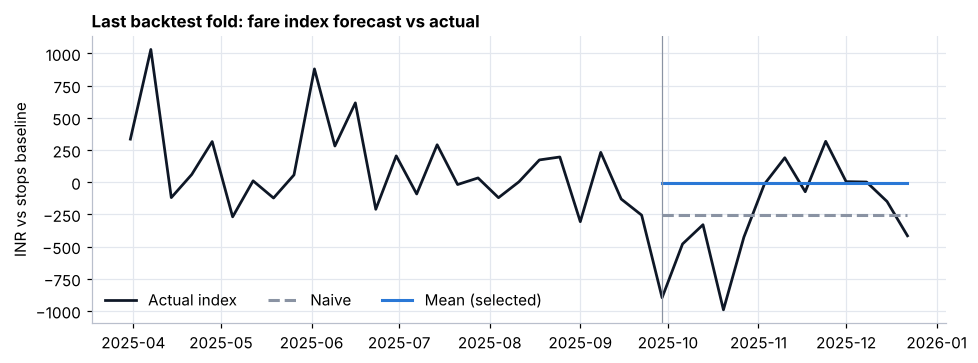

In [10]:
o = ORIGINS[-1]
tr, te = df[df.wk < o], df[(df.wk >= o) & (df.wk < o + H)]
y = weekly_index(tr, tr.groupby("stops").price.mean())
actual = weekly_index(df[df.wk < o + H], tr.groupby("stops").price.mean()).iloc[-H - 26:]
wks = lambda a, b: START_W + pd.to_timedelta(np.arange(a, b) * 7, unit="D")

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(wks(o - 26, o + H), actual.values, color=INK, lw=1.8, label="Actual index")
for name, col, ls in [("Naive", GREY, "--"), (BEST, BLUE, "-")]:
    ax.plot(wks(o, o + H), ts_forecast(name, y.values, H), color=col, lw=2, ls=ls, label=name + (" (selected)" if name == BEST else ""))
ax.axvline(wks(o, o + 1)[0], color=GREY, lw=0.8)
ax.set_title("Last backtest fold: fare index forecast vs actual"); ax.set_ylabel("INR vs stops baseline")
ax.legend(frameon=False, ncol=3, loc="lower left"); plt.tight_layout(); plt.show()

## 6. Fair-price band

The band is the 10th to 90th percentile of out-of-sample errors of the selected model, per stop count. The older half of the backtest folds sets the band and the newer half checks whether it holds on unseen data.

In [11]:
errs = pd.concat([resid[(BEST, o)].assign(origin=o) for o in ORIGINS])
half = ORIGINS[len(ORIGINS) // 2]
band = lambda e: {s: tuple(g.err.quantile([0.10, 0.90])) for s, g in e.groupby("stops")}
BAND_CHECK, BAND = band(errs[errs.origin < half]), band(errs)
ALL_BANDS = {m: band(pd.concat([resid[(m, o)] for o in ORIGINS])) for m in TS_MODELS}

new = errs[errs.origin >= half]
inside = new.apply(lambda r: BAND_CHECK[r.stops][0] <= r.err <= BAND_CHECK[r.stops][1], axis=1)
print(f"Band set on older folds contains {inside.mean():.0%} of errors on newer, unseen folds (target 80%)")
pd.DataFrame(BAND, index=["lower (INR)", "upper (INR)"]).T.loc[["non-stop", "1 stop", "2 stops", "3 stops"]].round(0).astype(int)

Band set on older folds contains 80% of errors on newer, unseen folds (target 80%)


,lower (INR),upper (INR)
non-stop,-3817,3860
1 stop,-3738,3718
2 stops,-3802,3807
3 stops,-3998,3836


The band is about **±₹3,800** at every stop count. That width is the real spread of fares: two listings with the same stops differ by up to ₹10,000, and nothing in the data explains it.

## 7. Fare check function (used by the app)

In [12]:
STOP_MEAN = df.groupby("stops").price.mean()
IDX_FULL = weekly_index(df, STOP_MEAN)

def fit_level(name, y, h=60):
    n = len(y)
    if name == "Mean": fitted = np.full(n, y.mean())
    elif name == "Naive": fitted = np.r_[y[0], y[:-1]]
    elif name == "Seasonal naive (52)": fitted = np.r_[np.full(52, y[:52].mean()), y[:-52]]
    else:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            if name == "SES": m = SimpleExpSmoothing(y, initialization_method="estimated").fit()
            elif name == "Holt (damped)": m = ExponentialSmoothing(y, trend="add", damped_trend=True, initialization_method="estimated").fit()
            elif name == "ARIMA(1,0,1)": m = ARIMA(y, order=(1, 0, 1)).fit()
            else: m = SARIMAX(y, exog=fourier(0, n), order=(1, 0, 0)).fit(disp=False)
            fitted = np.asarray(m.fittedvalues)
    return fitted, np.asarray(ts_forecast(name, y, h))

LEVEL, LEVEL_FUT = fit_level(BEST, IDX_FULL.values)
LAST_DATE = df.date.max()

def check_fare(stops, date, price):
    w = (pd.Timestamp(date) - START_W).days // 7
    level = LEVEL[w] if w < N_WEEKS else LEVEL_FUT[min(w - N_WEEKS, len(LEVEL_FUT) - 1)]
    exp = STOP_MEAN[stops] + level
    lo, hi = BAND[stops]
    dev = price - exp
    peers = df[df.stops == stops].price
    return {"expected": round(exp), "fair_low": round(exp + lo), "fair_high": round(exp + hi),
            "deviation_pct": round(dev / exp * 100, 1),
            "verdict": "Underpriced" if dev < lo else "Overpriced" if dev > hi else "Fair",
            "cheaper_than_pct_of_peers": round((peers > price).mean() * 100),
            "basis": "observed" if pd.Timestamp(date) <= LAST_DATE else "projected"}

pd.DataFrame({f"INR {p:,}": check_fare("1 stop", "2024-06-15", p) for p in (6000, 8500, 13500)}).T

,expected,fair_low,fair_high,deviation_pct,verdict,cheaper_than_pct_of_peers,basis
"INR 6,000",8476,4738,12194,-29.2,Fair,77,observed
"INR 8,500",8476,4738,12194,0.3,Fair,49,observed
"INR 13,500",8476,4738,12194,59.3,Overpriced,1,observed


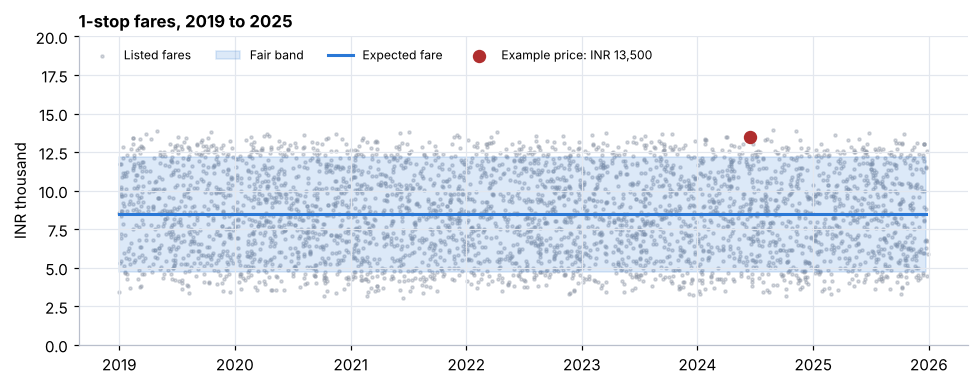

In [13]:
sub = df[df.stops == "1 stop"]
level_d = np.array([LEVEL[w] for w in sub.wk])
exp_line = STOP_MEAN["1 stop"] + pd.Series(LEVEL).reindex(range(N_WEEKS)).values
lo, hi = BAND["1 stop"]; weeks = wks(0, N_WEEKS)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.scatter(sub.date, sub.price / 1000, s=4, color=GREY, alpha=0.35, label="Listed fares")
ax.fill_between(weeks, (exp_line + lo) / 1000, (exp_line + hi) / 1000, color=BLUE, alpha=0.16, label="Fair band")
ax.plot(weeks, exp_line / 1000, color=BLUE, lw=2, label="Expected fare")
ax.scatter([pd.Timestamp("2024-06-15")], [13.5], s=60, color="#b02e2e", zorder=3, label="Example price: INR 13,500")
ax.set_title("1-stop fares, 2019 to 2025"); ax.set_ylabel("INR thousand"); ax.legend(frameon=False, ncol=4, loc="upper left", fontsize=8)
ax.set_ylim(0, 20); plt.tight_layout(); plt.show()

## 8. Export for the application

In [14]:
joblib.dump({
    "stop_mean": STOP_MEAN.to_dict(), "band": BAND, "bands": ALL_BANDS, "best": BEST, "level": LEVEL, "level_future": LEVEL_FUT,
    "idx_full": IDX_FULL.values, "start_week": START_W, "n_weeks": N_WEEKS, "last_date": LAST_DATE,
    "first_date": df.date.min(), "horizon": H, "ts_models": TS_MODELS,
}, OUT / "fairfare_v2.joblib")
df[["date", "wk", "origin", "dest", "airline", "stops", "price"]].to_csv(OUT / "clean_fares.csv.gz", index=False)
board.reset_index().rename(columns={"index": "model"}).to_csv(OUT / "backtest.csv", index=False)
stage1.reset_index().rename(columns={"index": "model"}).to_csv(OUT / "stage1.csv", index=False)
drivers.to_csv(OUT / "drivers.csv", index=False)
print(sorted(p.name for p in OUT.iterdir()))

['backtest.csv', 'clean_fares.csv.gz', 'drivers.csv', 'fairfare_v2.joblib', 'stage1.csv']
